# January temperature prediction with an MLP

This notebook trains a small multi-layer perceptron (MLP) using **January temperatures from 2020–2023**, uses **January 2024 only for validation/model selection**, then predicts **January 2025** and compares predictions with the recorded values.

Temperature is the only weather measurement used. The input `day_of_month` (1–31) is a calendar coordinate that tells the model which January day to predict; it is not another weather measurement. Each prediction is therefore an estimate for that day based on the patterns for the same day in past Januaries, not a forecast made from recent weather. No 2024 or 2025 temperatures are used to fit the selected model.

## 1. Load and check the data

The CSV starts with three non-table lines (location metadata and a blank line), so `skiprows=3` skips them. The temperature column is found by its stable name prefix so the degree symbol's encoding does not have to match exactly.

In [12]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("weather.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Put this notebook beside weather.csv.")

df = pd.read_csv(DATA_PATH, encoding="cp1252", skiprows=3, parse_dates=["time"])
temperature_columns = [column for column in df.columns if column.startswith("temperature_2m_mean")]
if "time" not in df.columns or len(temperature_columns) != 1:
    raise ValueError(f"Expected a time column and one temperature_2m_mean column; found {df.columns.tolist()}")
temperature_column = temperature_columns[0]

df = df[["time", temperature_column]].rename(columns={temperature_column: "temperature_c"})
if df["time"].duplicated().any():
    raise ValueError("The CSV contains duplicate dates.")
if df["temperature_c"].isna().any():
    raise ValueError("Temperature values are missing; handle them before training.")

df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["day_of_month"] = df["time"].dt.day
january = df.loc[df["month"].eq(1)].copy()
counts = january.groupby("year").size()
expected_years = set(range(2020, 2026))
if set(counts.index) != expected_years or not counts.eq(31).all():
    raise ValueError(f"Expected 31 January records for every year 2020–2025; got {counts.to_dict()}.")

print(f"Read {len(df):,} daily rows from {df['time'].min().date()} through {df['time'].max().date()}.")
print("January rows by year:")
display(counts.rename("rows").to_frame())
display(january.groupby("year")["temperature_c"].agg(["mean", "std", "min", "max"]).round(2))

Read 2,192 daily rows from 2020-01-01 through 2025-12-31.
January rows by year:


,rows
year,
2020,31
2021,31
2022,31
2023,31
2024,31
2025,31


,mean,std,min,max
year,,,,
2020,-0.62,2.78,-8.9,3.3
2021,-6.70,6.35,-23.2,1.0
2022,-5.69,4.43,-15.9,2.4
2023,-3.84,4.67,-13.0,1.4
2024,-10.59,9.62,-28.1,2.2
2025,-4.26,5.27,-15.8,3.4


## 2. Make chronological train, validation, and test sets

The split follows the requested years exactly. The input is day of month, and the target is that day's mean temperature. The scaler is part of each pipeline, so it is fit on the training inputs only. We do not refit on the validation year after choosing a model, keeping the January 2025 evaluation independent.

In [13]:
train = january.loc[january["year"].between(2020, 2023)].copy()
validation = january.loc[january["year"].eq(2024)].copy()
test = january.loc[january["year"].eq(2025)].copy()

FEATURE = "day_of_month"
TARGET = "temperature_c"
X_train = train[[FEATURE]]
y_train = train[TARGET]
X_validation = validation[[FEATURE]]
y_validation = validation[TARGET]
X_test = test[[FEATURE]]
y_test = test[TARGET]

print(f"Training:   {len(train)} rows, {train['year'].min()}–{train['year'].max()}")
print(f"Validation: {len(validation)} rows, {validation['year'].unique().item()}")
print(f"Test:       {len(test)} rows, {test['year'].unique().item()}")
display(train.head())

Training:   124 rows, 2020–2023
Validation: 31 rows, 2024
Test:       31 rows, 2025


,time,temperature_c,year,month,day_of_month
0,2020-01-01,-0.0,2020,1,1
1,2020-01-02,2.0,2020,1,2
2,2020-01-03,1.8,2020,1,3
3,2020-01-04,-1.3,2020,1,4
4,2020-01-05,-6.7,2020,1,5


## 3. Select an MLP using January 2024

We compare a small, pre-declared set of hidden-layer sizes and select the model with the lowest January 2024 MAE. The validation data is used for model selection, not for fitting. A simple baseline predicts the training-set average for the corresponding day of January; it uses only the same temperature history and calendar coordinate.

In [14]:
HIDDEN_LAYER_OPTIONS = [(4,), (8,), (4, 2)]
RANDOM_STATE = 42

def make_model(hidden_layer_sizes):
    return make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="tanh",
            solver="lbfgs",
            alpha=1.0,
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    )

def regression_metrics(actual, predicted):
    return {
        "MAE (°C)": mean_absolute_error(actual, predicted),
        "RMSE (°C)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

candidate_models = {}
validation_rows = []
for hidden_sizes in HIDDEN_LAYER_OPTIONS:
    model = make_model(hidden_sizes)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train, y_train)
    candidate_models[hidden_sizes] = model
    pred = model.predict(X_validation)
    validation_rows.append({
        "hidden layers": str(hidden_sizes),
        **regression_metrics(y_validation, pred),
    })

validation_results = pd.DataFrame(validation_rows).set_index("hidden layers")
best_candidate_index = int(validation_results["MAE (°C)"].to_numpy().argmin())
selected_hidden_sizes = HIDDEN_LAYER_OPTIONS[best_candidate_index]
validation_results = validation_results.sort_values("MAE (°C)")
selected_model = candidate_models[selected_hidden_sizes]
print(f"Selected hidden-layer sizes: {selected_hidden_sizes}")
display(validation_results.round(3))

baseline_by_day = train.groupby(FEATURE)[TARGET].mean()
validation_baseline = X_validation[FEATURE].map(baseline_by_day).to_numpy()
print("Validation comparison (January 2024):")
display(pd.DataFrame(
    [
        {"model": "MLP", **regression_metrics(y_validation, selected_model.predict(X_validation))},
        {"model": "day-of-month training mean", **regression_metrics(y_validation, validation_baseline)},
    ]
).set_index("model").round(3))

Selected hidden-layer sizes: (4,)


,MAE (°C),RMSE (°C),R²
hidden layers,,,
"(4,)",8.879,11.153,-0.389
"(8,)",8.960,11.191,-0.398
"(4, 2)",9.016,11.220,-0.406


Validation comparison (January 2024):


,MAE (°C),RMSE (°C),R²
model,,,
MLP,8.879,11.153,-0.389
day-of-month training mean,9.117,11.425,-0.457


## 4. Predict January 2025 and compare with actual temperatures

The selected model remains fitted only on January 2020–2023. January 2025 temperatures are used only to score and visualize the predictions.

In [15]:
test_predictions = selected_model.predict(X_test)
test_baseline = X_test[FEATURE].map(baseline_by_day).to_numpy()

test_results = pd.DataFrame(
    [
        {"model": "MLP", **regression_metrics(y_test, test_predictions)},
        {"model": "day-of-month training mean", **regression_metrics(y_test, test_baseline)},
    ]
).set_index("model")
print("Held-out test comparison (January 2025):")
display(test_results.round(3))

predictions = test[["time", FEATURE, TARGET]].copy()
predictions["mlp_prediction_c"] = test_predictions
predictions["baseline_prediction_c"] = test_baseline
predictions["mlp_error_c"] = predictions["mlp_prediction_c"] - predictions[TARGET]
display(predictions.round(2))

Held-out test comparison (January 2025):


,MAE (°C),RMSE (°C),R²
model,,,
MLP,3.726,4.426,0.27
day-of-month training mean,3.898,4.747,0.16


C:\Users\teora\AppData\Local\Temp\ipykernel_19608\214058805.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions.round(2))


,time,day_of_month,temperature_c,mlp_prediction_c,baseline_prediction_c,mlp_error_c
1827,2025-01-01,1,-6.2,-3.04,-2.75,3.16
1828,2025-01-02,2,-9.6,-3.70,-4.10,5.90
1829,2025-01-03,3,-11.7,-4.51,-3.78,7.19
1830,2025-01-04,4,-11.4,-5.41,-4.85,5.99
1831,2025-01-05,5,-15.8,-6.30,-7.50,9.50
1832,2025-01-06,6,-9.8,-7.06,-6.82,2.74
1833,2025-01-07,7,-5.5,-7.59,-7.45,-2.09
1834,2025-01-08,8,-5.4,-7.81,-7.43,-2.41
1835,2025-01-09,9,-8.5,-7.67,-8.22,0.83
1836,2025-01-10,10,-5.9,-7.19,-9.07,-1.29


## 5. Graphs

The first chart shows validation performance used during model selection. The second and third charts show the held-out January 2025 predictions and errors.

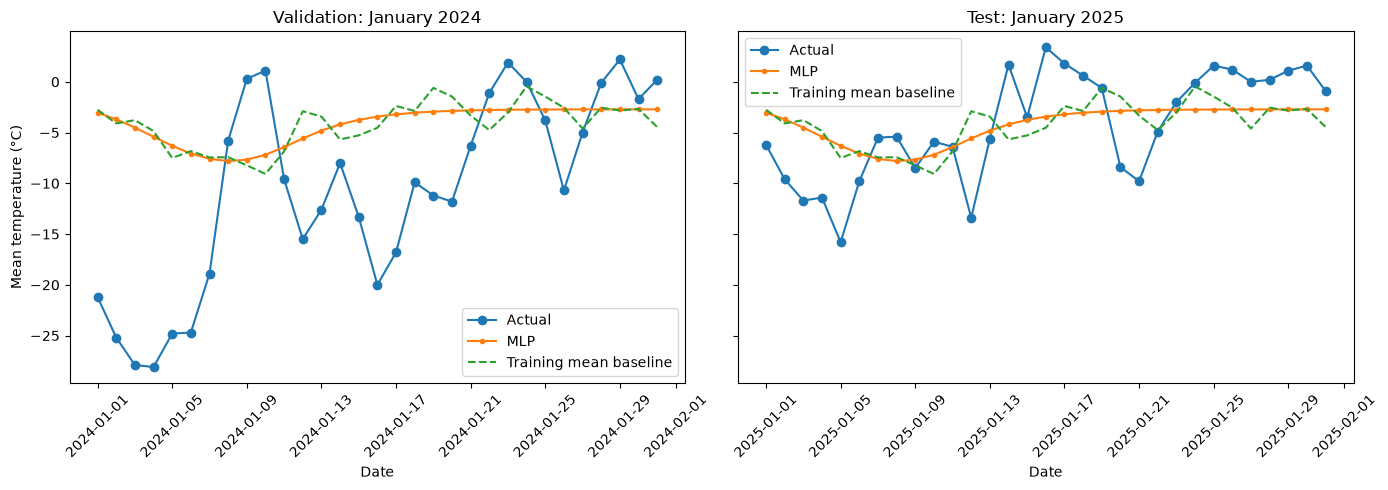

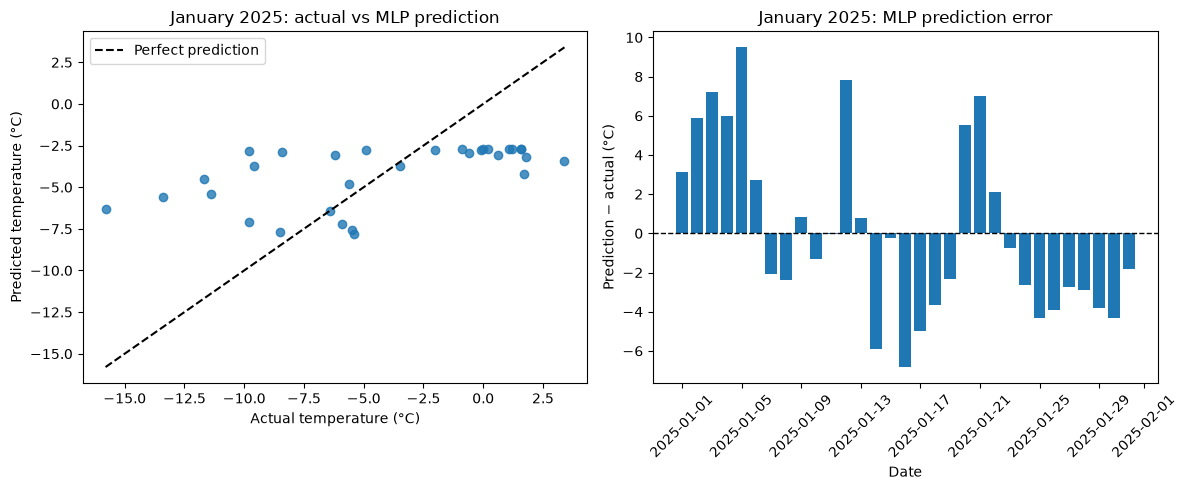

In [16]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(validation["time"], y_validation, marker="o", label="Actual")
axes[0].plot(validation["time"], selected_model.predict(X_validation), marker=".", label="MLP")
axes[0].plot(validation["time"], validation_baseline, linestyle="--", label="Training mean baseline")
axes[0].set_title("Validation: January 2024")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Mean temperature (°C)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].plot(test["time"], y_test, marker="o", label="Actual")
axes[1].plot(test["time"], test_predictions, marker=".", label="MLP")
axes[1].plot(test["time"], test_baseline, linestyle="--", label="Training mean baseline")
axes[1].set_title("Test: January 2025")
axes[1].set_xlabel("Date")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, test_predictions, alpha=0.8)
low = min(float(y_test.min()), float(test_predictions.min()))
high = max(float(y_test.max()), float(test_predictions.max()))
axes[0].plot([low, high], [low, high], "k--", label="Perfect prediction")
axes[0].set_title("January 2025: actual vs MLP prediction")
axes[0].set_xlabel("Actual temperature (°C)")
axes[0].set_ylabel("Predicted temperature (°C)")
axes[0].legend()

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].bar(test["time"], predictions["mlp_error_c"])
axes[1].set_title("January 2025: MLP prediction error")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Prediction − actual (°C)")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## Interpretation and limitations

- **MAE** is the average absolute error in °C; **RMSE** penalizes larger errors more; **R²** compares against predicting the test-set mean and can be negative.
- Check whether the MLP improves on the day-of-month training-mean baseline. A more complex model is not automatically better, especially with just 124 training observations.
- This is a deliberately constrained experiment: it learns a relationship between the day number and temperature using only four Januarys. It does **not** use prior-day weather, and it cannot react to actual weather conditions in January 2025. It is not a true operational daily weather forecast.
- For fair comparisons with other models, keep these exact year splits, inputs, and metrics fixed. Later, lagged temperature inputs can be tested as a separate experiment, with a clearly defined forecast horizon and no use of future actual temperatures as inputs.